In [1]:
# Core data processing
from pathlib import Path
import os
import textwrap

import numpy as np
import pandas as pd

# Machine learning
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_score,
    learning_curve,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Define input and output directories
#DATA_DIR = Path(".")
DATA_DIR = Path(
    "/Volumes/JAEONCHO/ADIC-AA/g_CD data"
)

event_folder = DATA_DIR / "events_g_CD"
sub_event_folder = DATA_DIR / "sub_events_g_CD"
trim_event_folder = DATA_DIR / "trim_events_g_CD"
trim_sub_event_folder = DATA_DIR / "trim_sub_events_g_CD"

trim_event_folder.mkdir(exist_ok=True)
trim_sub_event_folder.mkdir(exist_ok=True)


# Remove outputs from previous runs
for output_folder in (trim_event_folder, trim_sub_event_folder):
    for csv_path in output_folder.glob("*.csv"):
        csv_path.unlink()


# Remove first-level event outliers using MAD
for event_path in sorted(event_folder.glob("*.csv")):
    event_df = pd.read_csv(event_path)

    event_df["density"] = (
        event_df["num_sub_events"] / event_df["dwell_time_us"]
    )
    event_df["log_density"] = np.log(event_df["density"])

    median_log_density = event_df["log_density"].median()
    mad = np.median(
        np.abs(event_df["log_density"] - median_log_density)
    )

    if mad == 0:
        event_df["z"] = np.nan
    else:
        event_df["z"] = (
            0.6745
            * (event_df["log_density"] - median_log_density)
            / mad
        )

    trimmed_df = event_df[event_df["z"].abs() <= 3]

    if not trimmed_df.empty:
        trimmed_df.to_csv(
            trim_event_folder / event_path.name,
            index=False,
        )


# Match secondary events to retained first-level events
trimmed_event_files = {
    path.name[:19]: path
    for path in sorted(trim_event_folder.glob("*.csv"))
}

for sub_event_path in sorted(sub_event_folder.glob("*.csv")):
    recording_id = sub_event_path.name[:19]
    matching_event_path = trimmed_event_files.get(recording_id)

    if matching_event_path is None:
        continue

    sub_event_df = pd.read_csv(sub_event_path)
    retained_event_df = pd.read_csv(matching_event_path)

    def belongs_to_retained_event(row):
        match = retained_event_df[
            (retained_event_df["start_time_s"] <= row["sub_start_time_s"])
            & (retained_event_df["end_time_s"] >= row["sub_end_time_s"])
        ]
        return not match.empty

    trimmed_sub_event_df = sub_event_df[
        sub_event_df.apply(belongs_to_retained_event, axis=1)
    ]

    if not trimmed_sub_event_df.empty:
        trimmed_sub_event_df.to_csv(
            trim_sub_event_folder / sub_event_path.name,
            index=False,
        )


print(
    f"Retained files: {len(list(trim_event_folder.glob('*.csv')))} "
    f"first-level and "
    f"{len(list(trim_sub_event_folder.glob('*.csv')))} secondary-event files."
)

Retained files: 211 first-level and 211 secondary-event files.


In [3]:
# Assemble secondary-event data with first-level and baseline information

sub_event_folder = DATA_DIR / "trim_sub_events_g_CD"
event_folder = DATA_DIR / "trim_events_g_CD"
baseline_folder = DATA_DIR / "final_baseline_info_g_CD"


AA_CODE_MAP = {
    "A": "Ala",
    "C": "Cys",
    "D": "Asp",
    "E": "Glu",
    "F": "Phe",
    "G": "Gly",
    "H": "His",
    "I": "Ile",
    "K": "Lys",
    "L": "Leu",
    "M": "Met",
    "N": "Asn",
    "P": "Pro",
    "Q": "Gln",
    "R": "Arg",
    "S": "Ser",
    "T": "Thr",
    "V": "Val",
    "W": "Trp",
    "Y": "Tyr",
    "0": "ADIC",
}


# Match recording IDs to corresponding files

event_files = {
    path.name[:19]: path
    for path in sorted(event_folder.glob("*.csv"))
}

baseline_files = {
    path.name[:19]: path
    for path in sorted(baseline_folder.glob("*.csv"))
}

dataframes = []


for sub_event_path in sorted(sub_event_folder.glob("*.csv")):
    recording_id = sub_event_path.name[:19]

    event_path = event_files.get(recording_id)
    baseline_path = baseline_files.get(recording_id)

    if event_path is None:
        raise FileNotFoundError(
            f"No matching first-level event file for "
            f"{sub_event_path.name}"
        )

    if baseline_path is None:
        raise FileNotFoundError(
            f"No matching baseline file for "
            f"{sub_event_path.name}"
        )

    sub_event_df = pd.read_csv(sub_event_path)
    event_df = pd.read_csv(event_path)
    baseline_df = pd.read_csv(baseline_path)

    if baseline_df.empty:
        raise ValueError(
            f"Baseline file is empty: {baseline_path.name}"
        )

    open_pore_rms = baseline_df["rms"].iloc[0]


    def match_first_level_event(row):
        """Match a secondary event to its parent first-level event."""

        match = event_df[
            (event_df["start_time_s"] <= row["sub_start_time_s"])
            & (event_df["end_time_s"] >= row["sub_end_time_s"])
        ]

        if match.empty:
            return pd.Series([np.nan] * 5)

        first_level_event = match.iloc[0]

        return pd.Series(
            [
                first_level_event["dwell_time_us"],
                first_level_event["num_sub_events"],
                first_level_event["blockage_stdev"],
                (
                    f"{recording_id}_"
                    f"{first_level_event['event_index']}"
                ),
                first_level_event["blockage_current"],
            ]
        )


    sub_event_df[
        [
            "dwell_time_us",
            "num_sub_events",
            "first_level_stdev",
            "event_id",
            "first_level_blockage",
        ]
    ] = sub_event_df.apply(
        match_first_level_event,
        axis=1,
    )


    # Remove secondary events without a matching first-level event

    unmatched_count = sub_event_df["event_id"].isna().sum()

    if unmatched_count > 0:
        print(
            f"Warning: removing {unmatched_count} unmatched events "
            f"from {sub_event_path.name}"
        )

        sub_event_df = sub_event_df.dropna(
            subset=["event_id"]
        ).copy()


    # Convert secondary blockage to the combined current value

    sub_event_df["sub_blockage_current"] = (
        sub_event_df["first_level_blockage"]
        + sub_event_df["sub_blockage_current"]
    )


    # Assign the three-letter amino-acid label

    aa_code = sub_event_path.name[0]

    if aa_code not in AA_CODE_MAP:
        raise ValueError(
            f"Unknown amino-acid code in "
            f"{sub_event_path.name}"
        )

    sub_event_df["AA"] = AA_CODE_MAP[aa_code]
    sub_event_df["dataset_id"] = recording_id

    # I1: first-level blockage current
    sub_event_df["first_level_current"] = (
        sub_event_df["sub_mode_baseline"]
    )

    # σ0: recording-specific open-pore RMS noise
    sub_event_df["open_pore_rms"] = open_pore_rms


    selected_columns = [
        "sub_pre_interaction_current",
        "sub_post_interaction_current",
        "sub_blockage_current",
        "dwell_time_us",
        "dataset_id",
        "first_level_current",
        "first_level_stdev",
        "open_pore_rms",
        "event_id",
        "num_sub_events",
        "sub_dwell_time_us",
        "AA",
    ]

    dataframes.append(
        sub_event_df[selected_columns]
    )


df = pd.concat(
    dataframes,
    ignore_index=True,
)

print(f"Total secondary events: {len(df):,}")
display(df.head())

Total secondary events: 111,734


,sub_pre_interaction_current,sub_post_interaction_current,sub_blockage_current,dwell_time_us,dataset_id,first_level_current,first_level_stdev,open_pore_rms,event_id,num_sub_events,sub_dwell_time_us,AA
0,99.945060,100.280754,321.579678,34950.0,0_g_CD_250716__0003,127.80761,17.011557,3.578714,0_g_CD_250716__0003_0,4,210.0,ADIC
1,29.403685,106.221504,345.017250,34950.0,0_g_CD_250716__0003,127.80761,17.011557,3.578714,0_g_CD_250716__0003_0,4,190.0,ADIC
2,61.920162,108.042390,363.770630,34950.0,0_g_CD_250716__0003,127.80761,17.011557,3.578714,0_g_CD_250716__0003_0,4,540.0,ADIC
3,92.132560,105.987540,315.161106,34950.0,0_g_CD_250716__0003,127.80761,17.011557,3.578714,0_g_CD_250716__0003_0,4,150.0,ADIC
4,98.175040,106.445305,132.736197,259240.0,0_g_CD_250716__0003,126.80053,13.364807,3.578714,0_g_CD_250716__0003_4,13,120.0,ADIC


In [4]:
# Encode amino-acid labels

X_raw = df.drop(columns="AA").copy()
y_raw = df["AA"].copy()

label_encoder = LabelEncoder()

y = pd.Series(
    label_encoder.fit_transform(y_raw),
    index=df.index,
    name="AA_encoded",
)


# Use the parent first-level event as the grouping unit

groups = X_raw["event_id"].astype(str)

group_df = (
    pd.DataFrame({
        "group": groups,
        "y": y,
        "dataset_id": X_raw["dataset_id"],
    })
    .groupby(
        "group",
        as_index=False,
        sort=True,
    )
    .agg(
        y=("y", "first"),
        dataset_id=("dataset_id", "first"),
    )
)


# Create deterministic 60:20:20 splits within each AA class

train_groups = []
validation_groups = []
test_groups = []

for class_id in sorted(group_df["y"].unique()):
    class_groups = np.sort(
        group_df.loc[
            group_df["y"] == class_id,
            "group",
        ].to_numpy()
    )

    class_train, class_remaining = train_test_split(
        class_groups,
        test_size=0.4,
        random_state=42,
        shuffle=True,
    )

    class_validation, class_test = train_test_split(
        np.sort(class_remaining),
        test_size=0.5,
        random_state=42,
        shuffle=True,
    )

    train_groups.extend(class_train)
    validation_groups.extend(class_validation)
    test_groups.extend(class_test)


train_groups = set(train_groups)
validation_groups = set(validation_groups)
test_groups = set(test_groups)


# Ensure that every recording contributes at least one first-level event to the training set

for dataset_id in sorted(group_df["dataset_id"].unique()):
    dataset_groups = set(
        group_df.loc[
            group_df["dataset_id"] == dataset_id,
            "group",
        ]
    )

    if train_groups.isdisjoint(dataset_groups):
        candidate_groups = sorted(
            dataset_groups
            & (validation_groups | test_groups)
        )

        if not candidate_groups:
            raise ValueError(
                f"No group available for dataset {dataset_id}."
            )

        promoted_group = candidate_groups[0]

        validation_groups.discard(promoted_group)
        test_groups.discard(promoted_group)
        train_groups.add(promoted_group)


# Create row-level split masks

train_mask = groups.isin(train_groups)
validation_mask = groups.isin(validation_groups)
test_mask = groups.isin(test_groups)

assigned_count = (
    train_mask.astype(int)
    + validation_mask.astype(int)
    + test_mask.astype(int)
)

if not (assigned_count == 1).all():
    raise ValueError(
        "Each event must belong to exactly one data split."
    )


# Save the reproducible split assignment

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

split_assignment = pd.DataFrame({
    "event_id": groups,
    "AA": y_raw,
    "dataset_id": X_raw["dataset_id"],
    "split": np.select(
        [
            train_mask,
            validation_mask,
            test_mask,
        ],
        [
            "train",
            "validation",
            "test",
        ],
        default="unassigned",
    ),
})

split_assignment = (
    split_assignment
    .drop_duplicates(subset="event_id")
    .sort_values("event_id")
    .reset_index(drop=True)
)

split_assignment.to_csv(
    OUTPUT_DIR / "single_AA_split_assignment.csv",
    index=False,
)


# Apply the split

X_train_raw = X_raw.loc[train_mask].copy()
X_val_raw = X_raw.loc[validation_mask].copy()
X_test_raw = X_raw.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_val = y.loc[validation_mask].copy()
y_test = y.loc[test_mask].copy()

groups_train = groups.loc[train_mask].to_numpy()


# Confirm that σ0 is valid

for subset in (
    X_train_raw,
    X_val_raw,
    X_test_raw,
):
    if subset["open_pore_rms"].isna().any():
        raise ValueError(
            "open_pore_rms contains missing values."
        )

    if (subset["open_pore_rms"] <= 0).any():
        raise ValueError(
            "open_pore_rms contains zero or negative values."
        )


# Calculate local features using σ0

for subset in (
    X_train_raw,
    X_val_raw,
    X_test_raw,
):
    subset["baseline_ratio"] = (
        subset["sub_post_interaction_current"]
        / subset["first_level_current"]
    )

    subset["z_score"] = (
        subset["sub_post_interaction_current"]
        - subset["first_level_current"]
    ) / subset["open_pore_rms"]

    subset["squared_z_score"] = (
        subset["z_score"] ** 2
    )


# Calculate training-only aggregate terms for each recording

training_density = {}
training_event_count = {}

for dataset_id in sorted(
    X_train_raw["dataset_id"].unique()
):
    dataset = X_train_raw[
        X_train_raw["dataset_id"] == dataset_id
    ]

    secondary_event_count = len(dataset)

    total_first_level_dwell_time = (
        dataset
        .drop_duplicates(subset="event_id")[
            "dwell_time_us"
        ]
        .sum()
    )

    if total_first_level_dwell_time <= 0:
        raise ValueError(
            f"Invalid dwell time for dataset {dataset_id}."
        )

    training_density[dataset_id] = (
        secondary_event_count
        / total_first_level_dwell_time
    )

    training_event_count[dataset_id] = (
        secondary_event_count
    )


def derive_model_features(
    dataset,
    density_map,
    event_count_map,
):
    """Derive the four random-forest input features."""

    density = dataset["dataset_id"].map(
        density_map
    )

    event_count = dataset["dataset_id"].map(
        event_count_map
    )

    missing_mask = (
        density.isna()
        | event_count.isna()
    )

    if missing_mask.any():
        missing_datasets = dataset.loc[
            missing_mask,
            "dataset_id",
        ].unique()

        raise ValueError(
            "No training-derived aggregate values for: "
            f"{missing_datasets.tolist()}"
        )

    return pd.DataFrame(
        {
            "baseline_ratio": (
                dataset["baseline_ratio"]
            ),
            "z_score": (
                dataset["z_score"]
            ),
            "Per-time Impact": (
                dataset["squared_z_score"]
                / density
            ),
            "Per-event Impact": (
                dataset["squared_z_score"]
                / event_count
            ),
        },
        index=dataset.index,
    )


# Create final model-input tables

X_train = derive_model_features(
    X_train_raw,
    training_density,
    training_event_count,
)

X_val = derive_model_features(
    X_val_raw,
    training_density,
    training_event_count,
)

X_test = derive_model_features(
    X_test_raw,
    training_density,
    training_event_count,
)

X = pd.concat(
    [
        X_train,
        X_val,
        X_test,
    ]
)


print(
    f"Training: {len(X_train):,}; "
    f"validation: {len(X_val):,}; "
    f"test: {len(X_test):,}"
)

print(
    "Unique first-level events — "
    f"training: {len(train_groups):,}; "
    f"validation: {len(validation_groups):,}; "
    f"test: {len(test_groups):,}"
)

display(X.head())

Training: 66,417; validation: 22,939; test: 22,378
Unique first-level events — training: 5,100; validation: 1,698; test: 1,708


,baseline_ratio,z_score,Per-time Impact,Per-event Impact
0,0.784623,-7.691829,1.149636e+06,0.580041
1,0.831105,-6.031805,7.069617e+05,0.356693
2,0.845352,-5.522995,5.927214e+05,0.299054
3,0.829274,-6.097182,7.223698e+05,0.364467
17,0.817280,-6.519294,8.258524e+05,0.416678


In [5]:
# Train the random forest classifier
classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced_subsample",
)

classifier.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [6]:
# Evaluate model performance

cross_validation = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

cv_scores = cross_val_score(
    clone(classifier),
    X_train,
    y_train,
    cv=cross_validation,
    groups=groups_train,
    scoring="accuracy",
    n_jobs=-1,
)


# Test-set predictions
y_test_pred = classifier.predict(X_test)
y_test_proba = classifier.predict_proba(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)
validation_accuracy = classifier.score(X_val, y_val)

f1_micro = f1_score(
    y_test,
    y_test_pred,
    average="micro",
)
f1_macro = f1_score(
    y_test,
    y_test_pred,
    average="macro",
)
precision_micro = precision_score(
    y_test,
    y_test_pred,
    average="micro",
    zero_division=0,
)
recall_micro = recall_score(
    y_test,
    y_test_pred,
    average="micro",
    zero_division=0,
)

auc_macro = roc_auc_score(
    y_test,
    y_test_proba,
    multi_class="ovr",
    average="macro",
)
auc_micro = roc_auc_score(
    y_test,
    y_test_proba,
    multi_class="ovr",
    average="micro",
)


# Save performance metrics
performance_metrics = pd.DataFrame(
    {
        "metric": [
            "test_accuracy",
            "validation_accuracy",
            "cross_validation_mean",
            "f1_micro",
            "f1_macro",
            "precision_micro",
            "recall_micro",
            "auc_macro",
            "auc_micro",
        ],
        "value": [
            test_accuracy,
            validation_accuracy,
            cv_scores.mean(),
            f1_micro,
            f1_macro,
            precision_micro,
            recall_micro,
            auc_macro,
            auc_micro,
        ],
    }
)

performance_metrics.to_csv(
    OUTPUT_DIR / "single_AA_performance_metrics.csv",
    index=False,
)

cv_results = pd.DataFrame({
    "fold": np.arange(1, len(cv_scores) + 1),
    "accuracy": cv_scores,
})
cv_results.to_csv(
    OUTPUT_DIR / "single_AA_cross_validation_scores.csv",
    index=False,
)

display(performance_metrics)
print("Cross-validation scores:", cv_scores)

,metric,value
0,test_accuracy,0.973367
1,validation_accuracy,0.952788
2,cross_validation_mean,0.955667
3,f1_micro,0.973367
4,f1_macro,0.927695
5,precision_micro,0.973367
6,recall_micro,0.973367
7,auc_macro,0.997412
8,auc_micro,0.997937


Cross-validation scores: [0.93908666 0.949556   0.96264936 0.95642901 0.97061212]


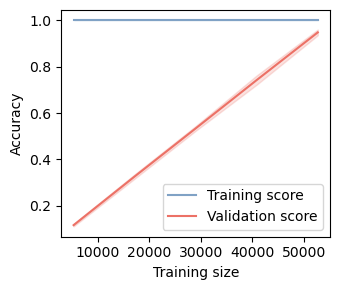

In [7]:
# Generate and plot the learning curve

train_sizes, train_scores, validation_scores = learning_curve(
    clone(classifier),
    X_train,
    y_train,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=cross_validation,
    groups=groups_train,
    scoring="accuracy",
    n_jobs=-1,
)

training_mean = train_scores.mean(axis=1)
training_std = train_scores.std(axis=1)

validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)


plt.figure(figsize=(3.5, 3))

plt.plot(
    train_sizes,
    training_mean,
    label="Training score",
    color="#80A2C5",
)
plt.fill_between(
    train_sizes,
    training_mean - training_std,
    training_mean + training_std,
    color="#80A2C5",
    alpha=0.2,
)

plt.plot(
    train_sizes,
    validation_mean,
    label="Validation score",
    color="#EC7166",
)
plt.fill_between(
    train_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    color="#EC7166",
    alpha=0.2,
)

plt.xlabel("Training size")
plt.ylabel("Accuracy")
#plt.ylim(0.70, 1.03)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "single_AA_learning_curve.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

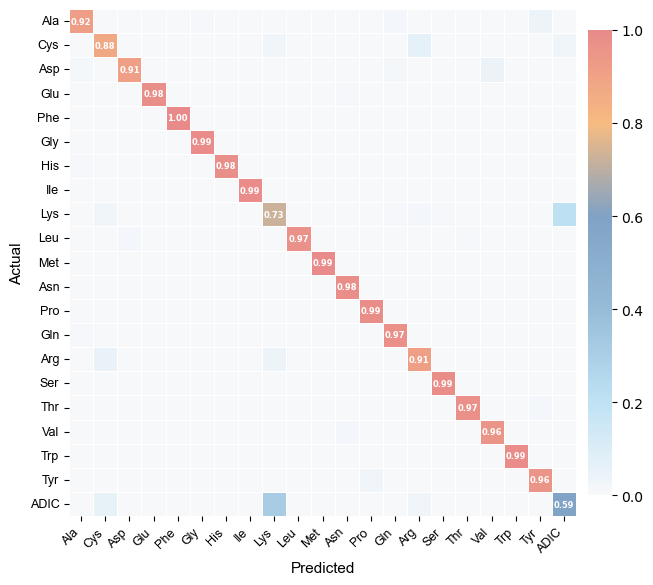

In [8]:
# Confusion matrix

from matplotlib.colors import LinearSegmentedColormap

custom_order = [
    "Ala", "Cys", "Asp", "Glu", "Phe", "Gly", "His",
    "Ile", "Lys", "Leu", "Met", "Asn", "Pro", "Gln",
    "Arg", "Ser", "Thr", "Val", "Trp", "Tyr", "ADIC",
]

custom_order_encoded = label_encoder.transform(custom_order)

y_test_pred = classifier.predict(X_test)

confusion_mtx = confusion_matrix(
    y_test,
    y_test_pred,
    labels=custom_order_encoded,
)

# Normalize each actual class by its total number of observations.
confusion_mtx_normalized = np.divide(
    confusion_mtx.astype(float),
    confusion_mtx.sum(axis=1, keepdims=True),
    out=np.zeros_like(confusion_mtx, dtype=float),
    where=confusion_mtx.sum(axis=1, keepdims=True) != 0,
)

# Color palette 
paper_warm = LinearSegmentedColormap.from_list(
    "paper_warm",
    [
        "#F7F8FA",
        "#BFE2F4",
        "#96BCD8",
        "#80A2C5",
        "#F7BB81",
        "#E88A8A",
    ],
    N=256,
)

# Display values only along the diagonal.
annotations = np.full(
    confusion_mtx_normalized.shape,
    "",
    dtype=object,
)

for i in range(len(custom_order)):
    annotations[i, i] = f"{confusion_mtx_normalized[i, i]:.2f}"

plt.figure(figsize=(7, 6))

ax = sns.heatmap(
    confusion_mtx_normalized,
    annot=annotations,
    fmt="",
    cmap=paper_warm,
    vmin=0,
    vmax=1,
    xticklabels=custom_order,
    yticklabels=custom_order,
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar=True,
    annot_kws={
        "size": 6,
        "weight": "bold",
        "color": "white",
    },
    cbar_kws={
        "shrink": 0.9,
        "pad": 0.02,
    },
)

plt.xlabel("Predicted", fontsize=11, fontfamily="Arial")
plt.ylabel("Actual", fontsize=11, fontfamily="Arial")

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks(
    rotation=0,
    fontsize=9,
    fontfamily="Arial",
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "single_AA_confusion_matrix.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

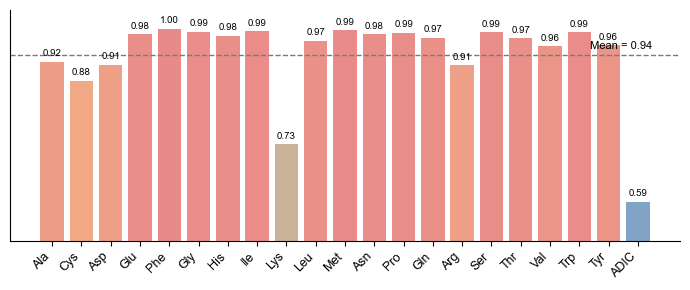

In [9]:
# Class-wise true-positive rate

from matplotlib.colors import Normalize

true_positive_rates = np.diag(confusion_mtx_normalized)

# Use the same colormap and value range as the confusion matrix.
color_norm = Normalize(vmin=0, vmax=1)
bar_colors = paper_warm(color_norm(true_positive_rates))

mean_tpr = true_positive_rates.mean()

plt.figure(figsize=(7, 3))

bars = plt.bar(
    custom_order,
    true_positive_rates,
    color=bar_colors,
    edgecolor="none",
)

# Mean true-positive rate
plt.axhline(
    mean_tpr,
    color="#7A7A7A",
    linestyle="--",
    linewidth=1,
)

plt.text(
    len(custom_order) - 0.5,
    mean_tpr + 0.008,
    f"Mean = {mean_tpr:.2f}",
    ha="right",
    va="bottom",
    fontsize=8,
    fontfamily="Arial",
)

# Value labels
for bar, value in zip(bars, true_positive_rates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.008,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=7,
        fontfamily="Arial",
    )

lower_limit = max(
    0,
    np.floor((true_positive_rates.min() - 0.05) * 10) / 10,
)

plt.ylim(lower_limit, 1.04)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks([])

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "single_AA_true_positive_rate.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

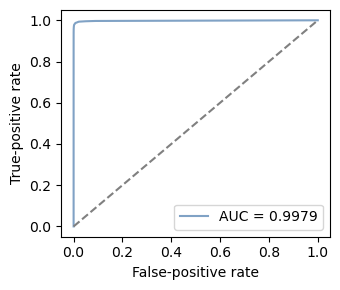

In [10]:
# Generate the micro-averaged ROC curve

number_of_classes = len(label_encoder.classes_)

y_test_binary = np.eye(number_of_classes)[
    y_test.to_numpy()
]

false_positive_rate, true_positive_rate, _ = roc_curve(
    y_test_binary.ravel(),
    y_test_proba.ravel(),
)

micro_roc_auc = auc(
    false_positive_rate,
    true_positive_rate,
)


# Save numerical source data
roc_curve_df = pd.DataFrame({
    "false_positive_rate": false_positive_rate,
    "true_positive_rate": true_positive_rate,
})

roc_curve_df.to_csv(
    OUTPUT_DIR / "single_AA_ROC_curve.csv",
    index=False,
)


# Plot
plt.figure(figsize=(3.5, 3))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    label=f"AUC = {micro_roc_auc:.4f}",
    color="#80A2C5",
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
)

plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "single_AA_ROC_curve.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

,Feature,Importance
0,Per-event Impact,0.302136
1,Per-time Impact,0.247938
2,Baseline Ratio,0.236064
3,Z Score,0.213862


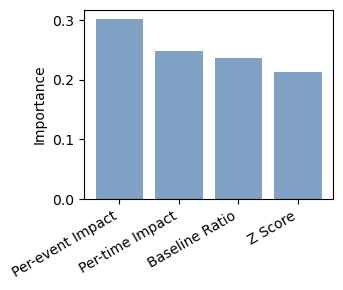

In [11]:
# Calculate and plot feature importance

feature_name_map = {
    "baseline_ratio": "Baseline Ratio",
    "z_score": "Z Score",
    "Per-time Impact": "Per-time Impact",
    "Per-event Impact": "Per-event Impact",
}

feature_importance_df = pd.DataFrame({
    "Feature": [
        feature_name_map.get(column, column)
        for column in X_train.columns
    ],
    "Importance": classifier.feature_importances_,
})

feature_importance_df = (
    feature_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)


# Save numerical source data
feature_importance_df.to_csv(
    OUTPUT_DIR / "single_AA_feature_importance.csv",
    index=False,
)

display(feature_importance_df)


# Plot
plt.figure(figsize=(3.5, 3))

plt.bar(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"],
    color="#80A2C5",
)

plt.xlabel("")
plt.ylabel("Importance")
plt.xticks(rotation=30, ha="right", fontsize=10)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "single_AA_feature_importance.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

